# Biology problems

Three mathematically explicit problems in cell-therapy assay interpretation. All values are synthetic. The code exposes units, model assumptions, boundary behavior and independent checks.

## Setup

Run from the repository root after installing `requirements.lock`. The validation runner executes this notebook and retains a separate executed copy. All code blocks below run against the same versioned implementation.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

import assay_math

OUT = Path("artifacts/run/assay_math")

## 1. Finite ligand and receptor binding

Problem: receptor total = 100 nM, ligand total = 10 nM, Kd = 1 nM. Find bound complex and receptor occupancy. Derive (R−C)(L−C)=Kd·C from mass balance and one-to-one equilibrium. Solve the quadratic with a cancellation-resistant expression, then check against a bracketed numerical root. C cannot exceed min(R,L). The common L/(Kd+L) expression requires free ligand, so substituting total ligand is invalid when depletion matters.

## 2. Counting beads and uncertainty

Problem: 120 target events, 800 bead events, 10,000 beads added and 100 µL sample. The concentration is (120/800)×(10,000/100) = 15 cells/µL. Condition on the observed target-plus-bead count to obtain an exact binomial Clopper-Pearson interval, then transform its limits to a Poisson-rate ratio. The interval excludes uncertainty in pipetting, mixing and viability. A zero target count gives an estimate of zero with a positive upper bound; zero observed beads makes the concentration undefined.

## 3. Rare-cell detection with background

Without background, the chance of at least one true detection is 1−(1−p·s)^N. Solve for the smallest integer N achieving the requested confidence, and verify N and N−1. Then add a per-cell false-positive rate: an “any positive” rule can produce frequent false alarms. Calibrate a count threshold using the binomial blank distribution and calculate power separately. A sample-size calculation alone is not an experimentally validated limit of detection.

## Execute the complete analysis

Inspect the returned results and tables. No outcome is hand-written into the code or edited to create a better story.

In [2]:
summary = assay_math.run(OUT)
print(json.dumps(summary, indent=2))

{
  "source": "Synthetic reference problems, not product-specific assay specifications",
  "binding_example": {
    "receptor_nM": 100,
    "total_ligand_nM": 10,
    "kd_nM": 1,
    "complex_nM": 9.890242272075156,
    "exact_occupancy": 0.09890242272075156,
    "incorrect_free_ligand_shortcut": 0.9090909090909091
  },
  "bead_count_example": {
    "cells_per_ul": 15.0,
    "ci95": [
      12.27625843082485,
      18.193146221323627
    ]
  },
  "no_background_cells_for_95_percent_detection": 31533,
  "background_aware_design": {
    "n_cells": 30000,
    "positive_threshold": 7,
    "blank_false_positive_probability": 0.03350097375082747,
    "power": 0.36956854223016367,
    "naive_one_positive_blank_rate": 0.950220399630148
  },
  "assumptions": [
    "Binding assumes one-to-one equilibrium in a well-mixed volume and consistent concentration units; no avidity or kinetics.",
    "Bead interval conditions on total observed target+bead events; known bead addition/volume, independent P

9.890242272075156
0.09890242272075156


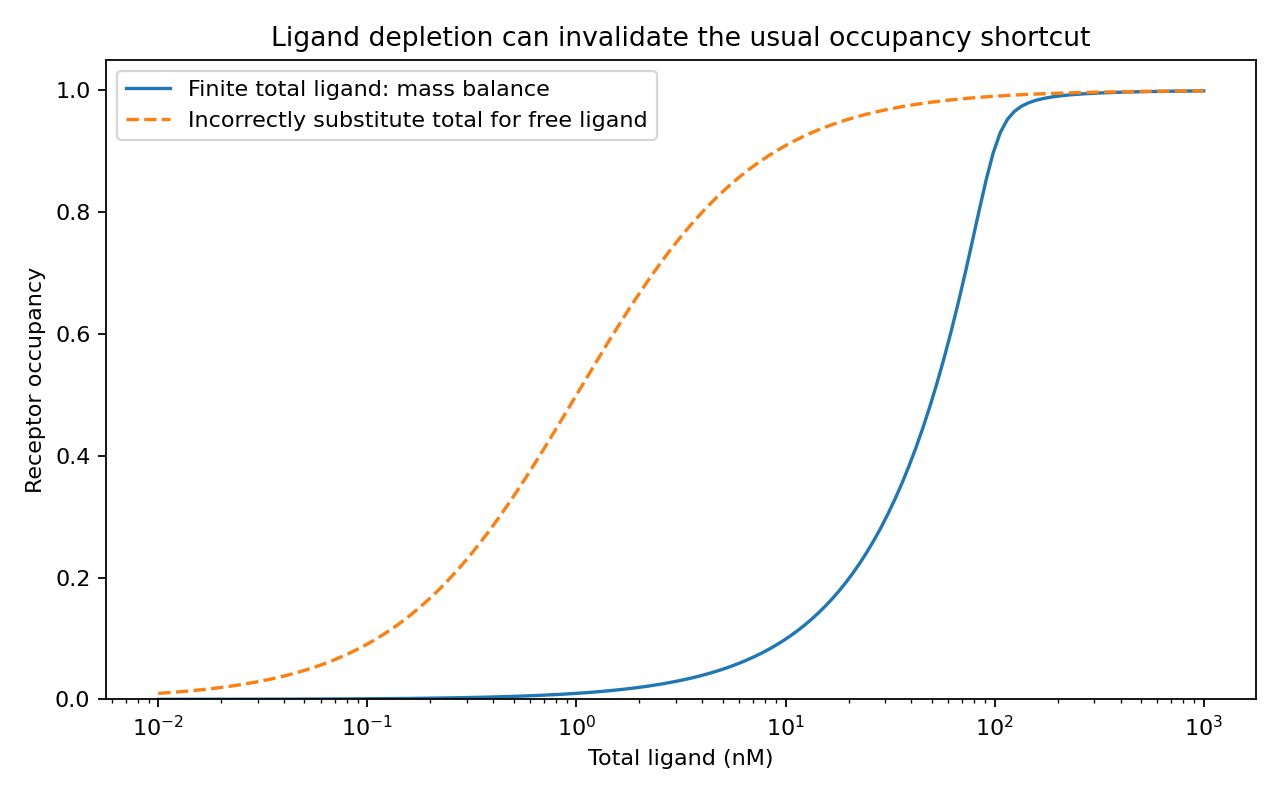

In [3]:
print(assay_math.complex_concentration(100, 10, 1))
print(assay_math.occupancy(100, 10, 1))
display(Image(filename=str(OUT / "binding.png")))

In [4]:
print(assay_math.bead_count(120, 800, 10_000, 100))
print(assay_math.bead_count(0, 800, 10_000, 100))

{'cells_per_ul': 15.0, 'ci95': [np.float64(12.27625843082485), np.float64(18.193146221323627)]}
{'cells_per_ul': 0.0, 'ci95': [0.0, np.float64(0.4621746795336188)]}


,n_cells,positive_threshold,blank_false_positive_probability,power,naive_one_positive_blank_rate
0,5000,3,0.014382,0.075734,0.393485
1,10000,4,0.018982,0.133933,0.632139
2,20000,6,0.016558,0.199395,0.864678
3,30000,7,0.033501,0.369569,0.950220
4,50000,10,0.031821,0.510374,0.993264
5,100000,16,0.048732,0.815991,0.999955


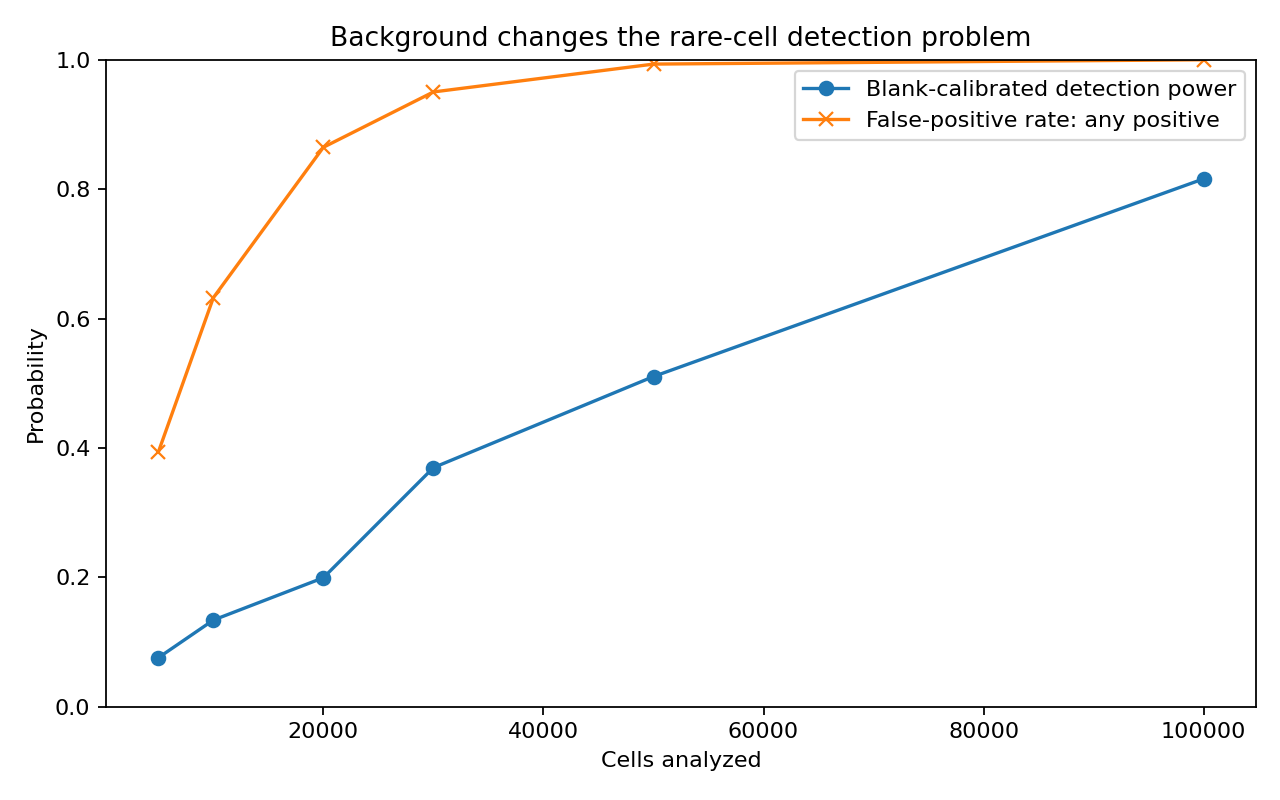

In [5]:
display(pd.read_csv(OUT / "rare_event_power.csv"))
display(Image(filename=str(OUT / "rare_event_power.png")))

## What was validated

`tests/` checks hand-calculated examples, independent formulations, malformed inputs and relevant invariants. `python scripts/validate.py` runs pytest, the full pipeline and this notebook. Passing these checks is bounded computational evidence, not clinical validation. See `reports/reference/assay_math/FINDINGS.md` for actual results and limitations.